<a href="https://colab.research.google.com/github/Csahoo009/ML-for-DA/blob/main/T7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from google.colab import files

# Load dataset directly from uploaded CSV
uploaded = files.upload()
# 1. Load dataset
df = pd.read_csv('indian_house_prices.csv')

# 2. Extract numeric feature columns (exclude non-numeric 'Location', 'City', and raw 'Price')
numeric_features = [col for col in df.select_dtypes(include=[np.number]).columns if col != 'Price']

X = df[numeric_features].fillna(df[numeric_features].mean())

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Number of Numeric Features for PCA: {len(numeric_features)}")
print("\nSample features:", numeric_features[:8])

Saving indian_house_prices.csv to indian_house_prices.csv
Dataset Shape: 32963 rows, 41 columns
Number of Numeric Features for PCA: 38

Sample features: ['Area', 'No. of Bedrooms', 'Resale', 'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack']


In [ ]:
# Feature scaling is mandatory: PCA is sensitive to differing measurement units/variances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Scaled feature matrix shape: {X_scaled.shape}")
print(f"Mean after scaling (approx 0): {np.round(X_scaled.mean(), 2)}")
print(f"Std dev after scaling (approx 1): {np.round(X_scaled.std(), 2)}")

Scaled feature matrix shape: (32963, 38)
Mean after scaling (approx 0): -0.0
Std dev after scaling (approx 1): 1.0


=== TOP 5 PRINCIPAL COMPONENTS ===
  Component  Individual Variance Ratio  Cumulative Variance Ratio
0       PC1                     0.9194                     0.9194
1       PC2                     0.0451                     0.9646
2       PC3                     0.0259                     0.9905
3       PC4                     0.0077                     0.9982
4       PC5                     0.0005                     0.9987


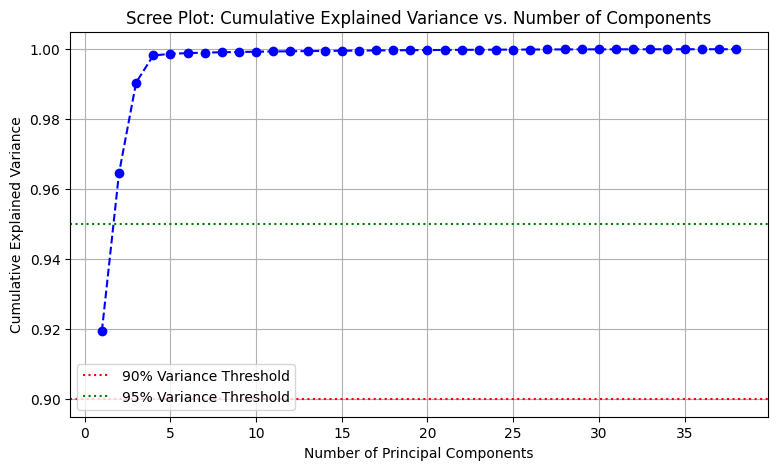

In [ ]:
# Fit PCA across all features to evaluate variance distribution
pca_full = PCA()
pca_full.fit(X_scaled)

# Calculate explained variance and cumulative explained variance
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Summary of top components
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(numeric_features))],
    "Individual Variance Ratio": np.round(explained_variance, 4),
    "Cumulative Variance Ratio": np.round(cumulative_variance, 4)
})

print("=== TOP 5 PRINCIPAL COMPONENTS ===")
print(var_df.head(5))

# Plot Scree Plot (Cumulative Variance)
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.90, color='r', linestyle=':', label='90% Variance Threshold')
plt.axhline(y=0.95, color='g', linestyle=':', label='95% Variance Threshold')

plt.title("Scree Plot: Cumulative Explained Variance vs. Number of Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Reduce the 38-dimensional space down to 2 components for 2D visualization
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    data=X_pca_2d,
    columns=['PC1', 'PC2']
)

# Attach class information ('Resale') for visualization
pca_df['Resale'] = df['Resale'].values
pca_df['Price_Lakhs'] = df['Price'] / 100000.0

print(f"Variance explained by PC1: {pca_2d.explained_variance_ratio_[0]*100:.2f}%")
print(f"Variance explained by PC2: {pca_2d.explained_variance_ratio_[1]*100:.2f}%")
print(f"Total variance retained : {np.sum(pca_2d.explained_variance_ratio_)*100:.2f}%\n")

print("=== Transformed 2D Dataset (First 5 Rows) ===")
print(pca_df.head())

Variance explained by PC1: 91.94%
Variance explained by PC2: 4.51%
Total variance retained : 96.46%

=== Transformed 2D Dataset (First 5 Rows) ===
        PC1       PC2  Resale  Price_Lakhs
0 -8.683834  3.257253       0       300.00
1 -8.601686 -0.571789       0        78.88
2 -8.857260 -0.454321       0        48.66
3 -9.125072  0.856200       0        83.58
4 -8.574007  0.864825       0        68.45


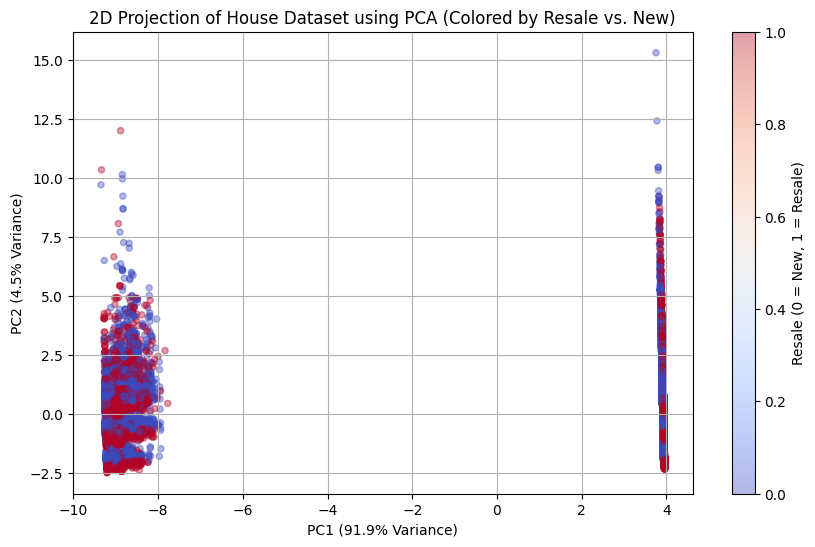

=== Top 5 Features Contributing Positively to PC1 ===
GolfCourse        0.169113
Wifi              0.169108
WashingMachine    0.169104
Wardrobe          0.169099
Sofa              0.169096
Name: PC1_Weight, dtype: float64

=== Top 5 Features Contributing Positively to PC2 ===
No. of Bedrooms       0.702086
Area                  0.699600
Children'splayarea    0.007142
SwimmingPool          0.007003
ClubHouse             0.006287
Name: PC2_Weight, dtype: float64


In [ ]:
# 1. Scatter Plot of 2D PCA Projections
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=pca_df['Resale'],
    cmap='coolwarm',
    alpha=0.4,
    s=20
)

plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.title("2D Projection of House Dataset using PCA (Colored by Resale vs. New)")
plt.colorbar(scatter, label='Resale (0 = New, 1 = Resale)')
plt.grid(True)
plt.show()

# 2. Feature Loadings (Which original features contribute most to PC1?)
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=['PC1_Weight', 'PC2_Weight'],
    index=numeric_features
)

print("=== Top 5 Features Contributing Positively to PC1 ===")
print(loadings.sort_values(by='PC1_Weight', ascending=False)['PC1_Weight'].head(5))

print("\n=== Top 5 Features Contributing Positively to PC2 ===")
print(loadings.sort_values(by='PC2_Weight', ascending=False)['PC2_Weight'].head(5))